## Packages

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

## Resources
General: 
- Hands on Machine Learning with scikit-learn and tensorflow, chapter 5, 6, 7

- Machine Learnia : https://www.youtube.com/watch?v=w_bLGK4Pteo


Decision Trees: 
- https://scikit-learn.org/stable/modules/tree.html
- https://www.youtube.com/watch?v=ZVR2Way4nwQ
- https://www.youtube.com/watch?v=sgQAhG5Q7iY

Random Forests:
- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- https://towardsdatascience.com/random-forest-in-python-24d0893d51c0
- https://www.youtube.com/watch?v=v6VJ2RO66Ag

SVM: 
- https://scikit-learn.org/stable/modules/svm.html
- https://dev.to/adityarohilla94/a-brief-introduction-to-support-vector-machine-4ne8
- https://www.youtube.com/watch?v=_YPScrckx28
- https://www.youtube.com/watch?v=Q7vT0--5VII

Learning Curves: 
- https://scikit-learn.org/stable/auto_examples/model_selection/plot_learning_curve.html#sphx-glr-auto-examples-model-selection-plot-learning-curve-py
- https://towardsdatascience.com/why-you-should-be-plotting-learning-curves-in-your-next-machine-learning-project-221bae60c53

Validation Curves 
- https://scikit-learn.org/stable/modules/learning_curve.html

- Take some time to read book sections for decision tree, random forest and SVM algorithms.
- Import these algorithms from scikit-learn and find the hyperparameter options that are available when they are instantiated.


## Decision trees

Explain here how they work in your own words:

In [21]:
# Load dataset
iris = load_iris()
X = iris.data[:, 2:] # petal length and width
y = iris.target

In [22]:
# Train a decision tree with max_depth=2
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(criterion='gini', max_depth=2, random_state=42)
clf.fit(X, y)



,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


### Visualization: export_graphviz

In [23]:
import os
import graphviz
from sklearn.tree import export_graphviz

# Indique à Python le chemin de l'installation Windows standard
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

dot_data = export_graphviz(
    clf,
    out_file=None,
    feature_names=iris.feature_names[2:],
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    special_characters=True,
)
graph = graphviz.Source(dot_data)
graph.render("iris_tree", format="png", cleanup=True)  # Crée automatiquement iris_tree.png


'iris_tree.png'

In [24]:
# open image with PIL
from PIL import Image
image = Image.open("iris_tree.png")
image.show()

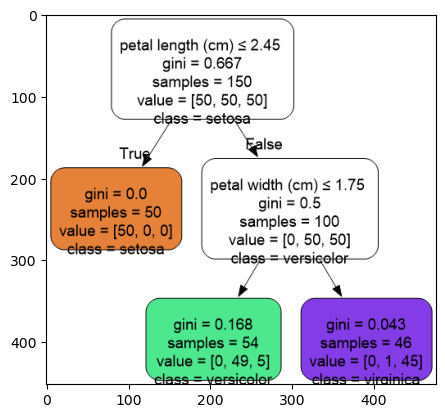

In [25]:
# open image with matplotlib
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img=mpimg.imread('iris_tree.png')
imgplot = plt.imshow(img)

### Visualization: plot_tree

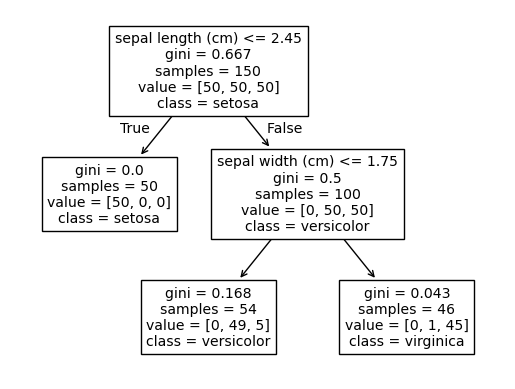

In [30]:
# visualize using the 'plot_tree' method (from the sklearn.tree module)
from sklearn.tree import plot_tree
plot = plot_tree(clf, feature_names = iris.feature_names[:2], class_names = iris.target_names)

Compute the predictions of a decision tree classifier on a test set and calculate all the classification metrics you know:


In [31]:
# split in train and test set
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score)

def split(X, y, test_size=0.2):
    return train_test_split(X, y, test_size=test_size, stratify=y, random_state=42)

def report(y_true, y_pred):
    # all the classification metrics in one call
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 3))
    print("Precision:", round(precision_score(y_true, y_pred, average='macro'), 3))
    print("Recall   :", round(recall_score(y_true, y_pred, average='macro'), 3))
    print("F1-score :", round(f1_score(y_true, y_pred, average='macro'), 3))
    print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))

X_train, X_test, y_train, y_test = split(X, y)

In [32]:
# fit classifier with max_depth=2
tree_clf = DecisionTreeClassifier(criterion='gini', max_depth=2, random_state=42)
tree_clf.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [33]:
# make predictions on the test set
y_pred_tree = tree_clf.predict(X_test)

In [34]:
# Print Accuracy
# Print Confusion matrix
# Print Precision
# Print Recall
# Print F1-score
report(y_test, y_pred_tree)

Accuracy : 0.933
Precision: 0.933
Recall   : 0.933
F1-score : 0.933
Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


## Random forests

Explain here how they work in your own words:

In [35]:
# fit a Random Forest classifier 

from sklearn.ensemble import RandomForestClassifier
rf_clf = RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42)
rf_clf.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [36]:
# make predictions on the test set
y_pred_rf = rf_clf.predict(X_test)

In [37]:
# Print Accuracy
# Print Confusion matrix
# Print Precision
# Print Recall
# Print F1-score
report(y_test, y_pred_rf)

Accuracy : 0.967
Precision: 0.97
Recall   : 0.967
F1-score : 0.967
Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


## SVM

Explain here how they work in your own words:

In [39]:
# Book example SVM: iris dataset
X_svm = iris.data[:, 2:]
y_svm = (iris.target == 2).astype(int)
X_train_s, X_test_s, y_train_s, y_test_s = split(X_svm, y_svm)

In [40]:
# fit a linear SVM classifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
svm_clf = make_pipeline(StandardScaler(), LinearSVC(C=1, random_state=42, max_iter=10000))
svm_clf.fit(X_train_s, y_train_s)

,steps,"[('standardscaler', ...), ('linearsvc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001


In [41]:
# make predictions on the test set
y_pred_svm = svm_clf.predict(X_test_s)

In [42]:
# Print Accuracy
# Print Confusion matrix
# Print Precision
# Print Recall
# Print F1-score
report(y_test_s, y_pred_svm)

Accuracy : 0.967
Precision: 0.976
Recall   : 0.95
F1-score : 0.961
Confusion matrix:
 [[20  0]
 [ 1  9]]


## Learning curves

### Book example

In [43]:
# Book Dataset p. 130 (noisy quadratic data)
np.random.seed(42)
m = 100
X_book = 6 * np.random.rand(m, 1) - 3
y_book = (0.5 * X_book ** 2 + X_book + 2 + np.random.randn(m, 1)).ravel()

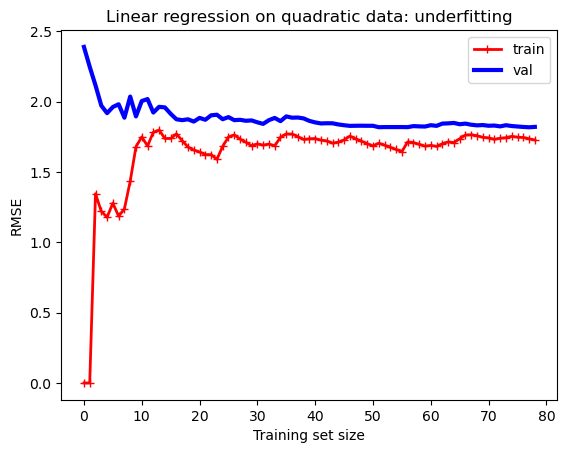

In [44]:
# Implement the book’s code on learning curves on the data he has used.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

def plot_learning_curves(model, X, y):
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=10)
    train_errors, val_errors = [], []
    for m in range(1, len(X_train)):
        model.fit(X_train[:m], y_train[:m])
        train_errors.append(mean_squared_error(y_train[:m], model.predict(X_train[:m])))
        val_errors.append(mean_squared_error(y_val, model.predict(X_val)))
    plt.plot(np.sqrt(train_errors), "r-+", linewidth=2, label="train")
    plt.plot(np.sqrt(val_errors), "b-", linewidth=3, label="val")
    plt.xlabel("Training set size"); plt.ylabel("RMSE"); plt.legend()

plot_learning_curves(LinearRegression(), X_book, y_book)
plt.title("Linear regression on quadratic data: underfitting")
plt.show()

Change the method so that instead of having an incremental training set size going from 1 to the size of X_train, you have a fixed set of training sizes.
For example: 

training_set_sizes = np.linspace(2, len(X_train), len(X_train), dtype='int')

or 

training_set_sizes = [1, 10, 20, 30, 40, 50, 60, 70, 80]

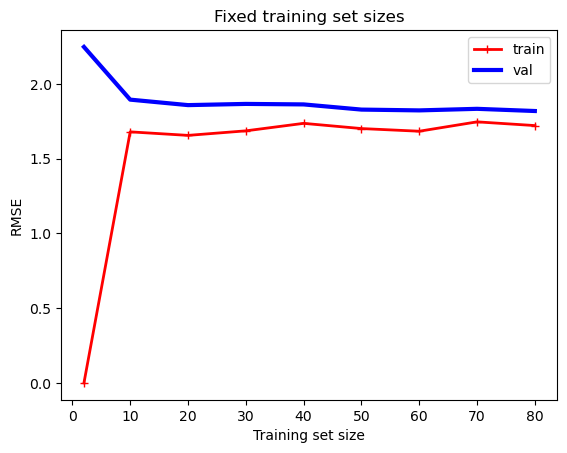

In [47]:
# Method that plots learning curves for a given estimator and training_set_sizes
def your_method_name_for_plotting_learning_curves(model, X_train, X_val, y_train, y_val,
                                                  training_set_sizes):
    train_errors, val_errors = [], []
    for m in training_set_sizes:
        model.fit(X_train[:m], y_train[:m])
        train_errors.append(mean_squared_error(y_train[:m], model.predict(X_train[:m])))
        val_errors.append(mean_squared_error(y_val, model.predict(X_val)))
    plt.plot(training_set_sizes, np.sqrt(train_errors), "r-+", linewidth=2, label="train")
    plt.plot(training_set_sizes, np.sqrt(val_errors), "b-", linewidth=3, label="val")
    plt.xlabel("Training set size"); plt.ylabel("RMSE"); plt.legend()
# create your method to plot your learning curves using the sklearn method learning_curve()
X_train_b, X_val_b, y_train_b, y_val_b = train_test_split(X_book, y_book, test_size=0.2, random_state=10)
sizes = [2, 10, 20, 30, 40, 50, 60, 70, 80]
your_method_name_for_plotting_learning_curves(LinearRegression(), X_train_b, X_val_b,
                                              y_train_b, y_val_b, sizes)
plt.title("Fixed training set sizes")
plt.show()

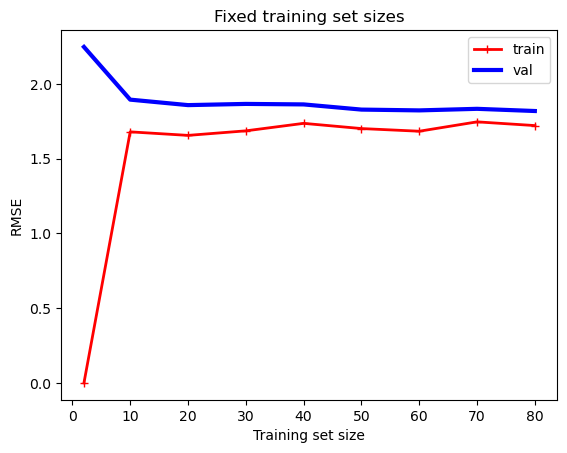

In [50]:
X_train_b, X_val_b, y_train_b, y_val_b = train_test_split(X_book, y_book, test_size=0.2, random_state=10)
sizes = [2, 10, 20, 30, 40, 50, 60, 70, 80]
your_method_name_for_plotting_learning_curves(LinearRegression(), X_train_b, X_val_b,
                                              y_train_b, y_val_b, sizes)
plt.title("Fixed training set sizes")
plt.show()

## Learning curves for classifiers

Implement a ML problem on a dataset you have already seen in the course. 

Produce a plot of a model which shows signs of underfitting, and one that shows signs of overfitting.

In [51]:
from sklearn.model_selection import learning_curve

def plot_learning_curve(estimator, title, X, y, axes=None, ylim=None, cv=None,
                        n_jobs=None, train_sizes=np.linspace(.1, 1.0, 5)):
    if axes is None:
        _, axes = plt.subplots(1, 1, figsize=(6, 4))
    if ylim is not None:
        axes.set_ylim(*ylim)
    sizes, train_scores, val_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes, scoring='accuracy')
    tr_m, tr_s = train_scores.mean(axis=1), train_scores.std(axis=1)
    va_m, va_s = val_scores.mean(axis=1), val_scores.std(axis=1)
    axes.fill_between(sizes, tr_m - tr_s, tr_m + tr_s, alpha=0.15, color="r")
    axes.fill_between(sizes, va_m - va_s, va_m + va_s, alpha=0.15, color="g")
    axes.plot(sizes, tr_m, 'o-', color="r", label="Training score")
    axes.plot(sizes, va_m, 'o-', color="g", label="Cross-validation score")
    axes.set_title(title); axes.set_xlabel("Training examples"); axes.set_ylabel("Accuracy")
    axes.legend(loc="best")
    return axes

## Decision trees learning curves

In [54]:
# import the dataset you want (noisy two-moons: swap in a course dataset if you prefer)
from sklearn.datasets import make_moons
X_m, y_m = make_moons(n_samples=1000, noise=0.35, random_state=42)


In [55]:
# do all the pre-rpocessing that is needed
X_tr, X_te, y_tr, y_te = split(X_m, y_m)
print(X_tr.shape, X_te.shape)

(800, 2) (200, 2)


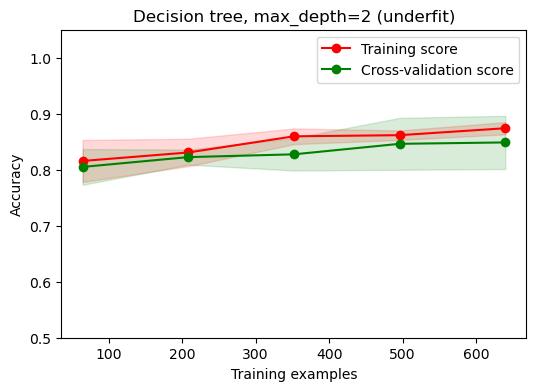

In [56]:
# Underfit model
# Train a decision tree with max_depth=2
plot_learning_curve(DecisionTreeClassifier(max_depth=2, random_state=42),
                    "Decision tree, max_depth=2 (underfit)", X_tr, y_tr, cv=5, ylim=(0.5, 1.05))
plt.show()

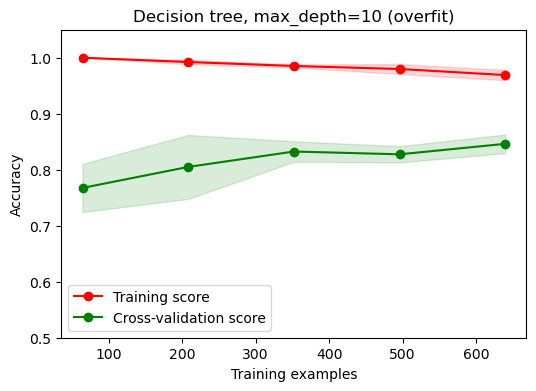

In [57]:
# Overfit model
# Train a decision tree with max_depth=10
plot_learning_curve(DecisionTreeClassifier(max_depth=10, random_state=42),
                    "Decision tree, max_depth=10 (overfit)", X_tr, y_tr, cv=5, ylim=(0.5, 1.05))
plt.show()

## Random forests classifier learning curves

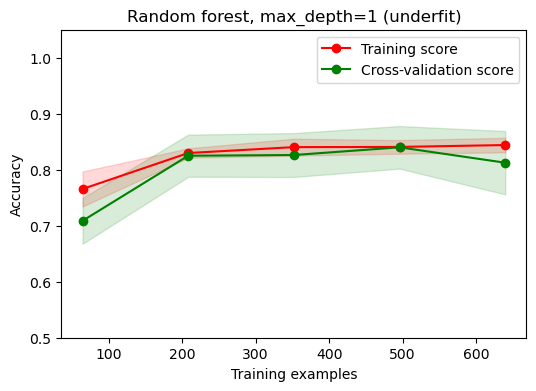

In [58]:
# Underfit model
plot_learning_curve(RandomForestClassifier(n_estimators=10, max_depth=1, random_state=42),
                    "Random forest, max_depth=1 (underfit)", X_tr, y_tr, cv=5, ylim=(0.5, 1.05))
plt.show()

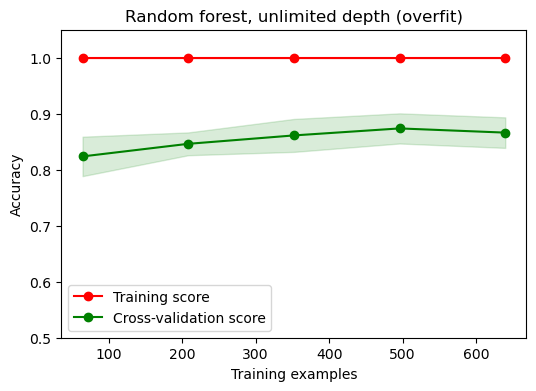

In [59]:
# Overfit model
plot_learning_curve(RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42),
                    "Random forest, unlimited depth (overfit)", X_tr, y_tr, cv=5, ylim=(0.5, 1.05))
plt.show()

## SVM

SVM Advantages:

- SVM’s are very good when we have no prior intuition on the data.
- They work very well with even unstructured and semi-structured data like text, Images and trees.
- The kernel trick is the real strength of SVMs. With an appropriate kernel function, we can solve almost any complex problem.
- Unlike neural networks, SVM are not solved for local optima.
- They scale relatively well to high dimensional data.
- SVM models have good generalization in practice, they are less prone to over-fitting than other models.

SVM Disadvantages:

- Choosing a “good” kernel function is not easy.
- Long training time for large datasets.
- Difficult to understand and interpret the final model, variable weights and individual impact.
- The SVM hyper parameters are Cost -C and gamma. It is not that easy to fine-tune these hyper-parameters. It is hard to visualize their impact.

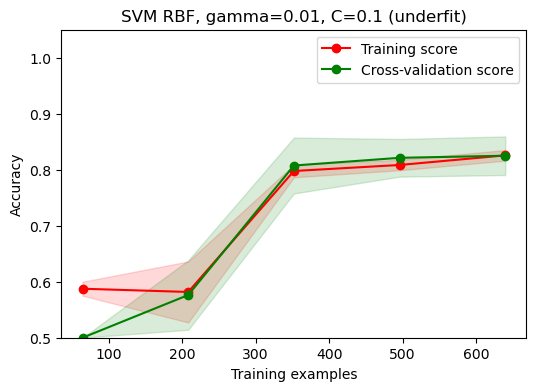

In [60]:
# Underfit model?
from sklearn.svm import SVC
plot_learning_curve(make_pipeline(StandardScaler(), SVC(kernel='rbf', gamma=0.01, C=0.1)),
                    "SVM RBF, gamma=0.01, C=0.1 (underfit)", X_tr, y_tr, cv=5, ylim=(0.5, 1.05))
plt.show()

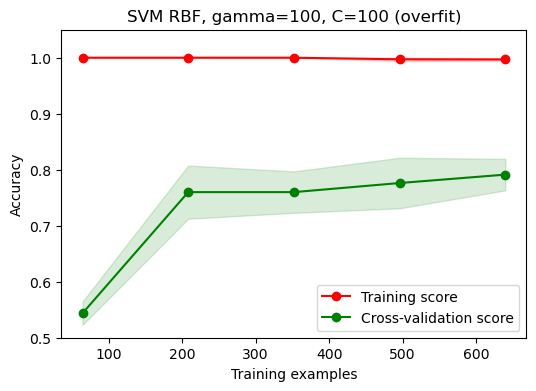

In [61]:
# Overfit model?
plot_learning_curve(make_pipeline(StandardScaler(), SVC(kernel='rbf', gamma=100, C=100)),
                    "SVM RBF, gamma=100, C=100 (overfit)", X_tr, y_tr, cv=5, ylim=(0.5, 1.05))
plt.show()

## Validation curves

Validation curves are a useful tool for improving the performance of a model by addressing issues such as overfitting or underfitting. Validation curves are related to learning curves, but instead of plotting the training and test accuracies as functions of the sample size, we vary the values of the model parameters. They are complementaru of GridSearch and make for a very nice visual tool for ypur algorithm optimization. 


In [62]:
from sklearn.model_selection import validation_curve
def plot_validation_curve(estimator, title, X, y, axes=None, ylim=None, cv=None, n_jobs=None,
                          param_range=None, paran_name=None):
    if axes is None:
        _, axes = plt.subplots(1, 1, figsize=(6, 4))
    if ylim is not None:
        axes.set_ylim(*ylim)
    train_scores, val_scores = validation_curve(
        estimator, X, y, param_name=paran_name, param_range=param_range,
        cv=cv, scoring='accuracy', n_jobs=n_jobs)
    tr_m, tr_s = train_scores.mean(axis=1), train_scores.std(axis=1)
    va_m, va_s = val_scores.mean(axis=1), val_scores.std(axis=1)
    axes.fill_between(param_range, tr_m - tr_s, tr_m + tr_s, alpha=0.15, color="r")
    axes.fill_between(param_range, va_m - va_s, va_m + va_s, alpha=0.15, color="g")
    axes.semilogx(param_range, tr_m, 'o-', color="r", label="Training score")
    axes.semilogx(param_range, va_m, 'o-', color="g", label="Cross-validation score")
    axes.set_title(title); axes.set_xlabel(paran_name); axes.set_ylabel("Accuracy")
    axes.legend(loc="best")
    return axes

Plot the validation curves for a chosen algorithm and vary 1 or 2 parameters of your choice.

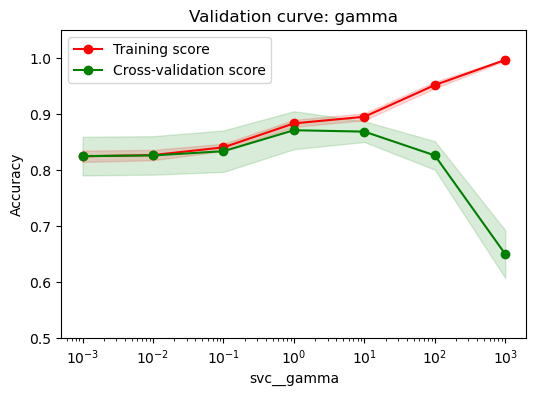

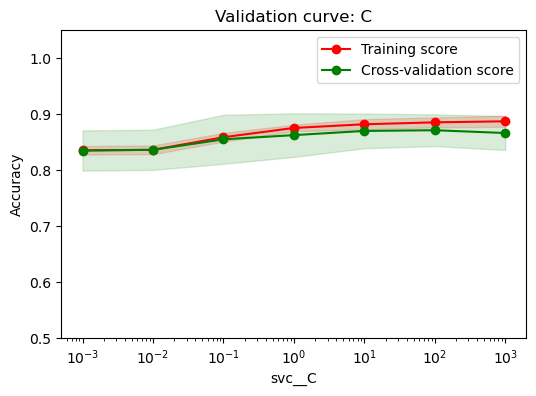

In [63]:
svm_pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
plot_validation_curve(svm_pipe, "Validation curve: gamma", X_tr, y_tr, cv=5,
                      param_range=np.logspace(-3, 3, 7), paran_name="svc__gamma", ylim=(0.5, 1.05))
plot_validation_curve(svm_pipe, "Validation curve: C", X_tr, y_tr, cv=5,
                      param_range=np.logspace(-3, 3, 7), paran_name="svc__C", ylim=(0.5, 1.05))
plt.show()

Do a GridSearch and see if the most optimal parameter is coherent with what you see on your validation curves

In [65]:
from sklearn.model_selection import GridSearchCV
param_grid = {"svc__gamma": np.logspace(-3, 3, 7), "svc__C": np.logspace(-3, 3, 7)}
grid = GridSearchCV(svm_pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_tr, y_tr)
print("Best params:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 3))
print("Test accuracy   :", round(grid.score(X_te, y_te), 3))


Best params: {'svc__C': np.float64(1.0), 'svc__gamma': np.float64(1.0)}
Best CV accuracy: 0.871
Test accuracy   : 0.93
